---
title: "Alpha Diversity - Assemblage Analysis"
date: last-modified
date-format: "YYYY-MM-DD HH:mm:ss"
format:
  html:
    toc: true
    toc-depth: 5
    toc-location: left
    embed-resources: true
    page-layout: full
    fig-width: 12
    fig-height: 8
    fig-responsive: true
execute:
  echo: false
---
<style>
  .cell-output-display img {
    width: 100% !important;
    max-width: 900px !important;
    height: auto !important;
  }
</style>
***

**Alpha diversity** describes the diversity within a single ecological unit or _**assemblage**_. It summarizes not only how many species are present, but also how their abundances are distributed.

Alpha diversity can be evaluated using Hill numbers, which represent different aspects of fungal diversity:
* q=0: Species richness — How many fungal species are present?
* q=1: Shannon diversity — How diverse is the assemblage when species are weighted according to their relative abundances?
* q=2: Inverse Simpson diversity — How diverse is the assemblage when greater emphasis is placed on common and dominant species?

Rarefaction and extrapolation, sample coverage, and asymptotic diversity estimates are used to determine whether sampling was sufficient and to make assemblages more fairly comparable.

This study defines assemblages as follows:
1. By transect
   * Transect A: conifer forest with access of reindeer
   * Transect B: conifer forest without access of reindeer
   * Transect C: broadleaf forest and accessed to tourists
2. Combination of transect and wood textures
   * Wood textures: hardwood and softwood
3. Combination of transect and wood types
   * Wood types: pine, birch, and spruce

This notebook calculates and visualizes diversity based on the various assemblages using the `iNEXT` R package.

In [1]:
# Load shared R functions for the Oulanka datasets.
source("../src/oulanka.R")
source("../src/make_plots.R")

In [2]:
citation("iNEXT")

To cite iNEXT in publications use:

  T. C. Hsieh, K. H. Ma and Anne Chao. 2025 iNEXT: iNterpolation and
  EXTrapolation for species diversity. R package version 3.0.2 URL:
  http://chao.stat.nthu.edu.tw/wordpress/software-download/.

  Anne Chao, Nicholas J. Gotelli, T. C. Hsieh, Elizabeth L. Sander, K.
  H. Ma, Robert K. Colwell, and Aaron M. Ellison 2014. Rarefaction and
  extrapolation with Hill numbers: a framework for sampling and
  estimation in species diversity studies. Ecological Monographs
  84:45-67.

To see these entries in BibTeX format, use 'print(<citation>,
bibtex=TRUE)', 'toBibtex(.)', or set
'options(citation.bibtex.max=999)'.

## 1. Loading the dataset
The study is focused on the saproxylic fungi communities.

In [3]:
# Load genus-level saproxylic community data
saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)

In [4]:
head(saproxylic_community_df)

,Aotearoamyces,Arachnopeziza,Ascocoryne,Atheliachaete,Botryobasidium,Ceraceomyces,Cistella,Claussenomyces,Collophora,Coniophora,⋯,Serpula,Sistotremastrum,Skvortzovia,Stereum,Teichospora,Trametes,Trechispora,Tympanis,Xenasmatella,Xylaria
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,⋯,7,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,⋯,2,0,0,0,0,0,0,0,0,0


In [5]:
# Load environment data
environment_df <- get_environment_data()

In [6]:
head(environment_df)

Transect,Tag,Sample.Number,Date.Collected,Days.Elapsed,Weeks.Elapsed,Months.Elapsed,Season,Wood.Type,Wood.Texture,Forward.Primer,Reverse.Primer
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
A,1,018561A,07/01/2022,13,2,2,Summer,Pine,Softwood,CACACGATCTGTGARTCATCGAATCTTTG,CACACGCTGTTCCTCCGCTTATTGATATGC
A,4,018561C,07/01/2022,13,2,2,Summer,Birch,Hardwood,CACATAGTCTGTGARTCATCGAATCTTTG,CACATGTCGTTCCTCCGCTTATTGATATGC
A,5,018561E,07/01/2022,13,2,2,Summer,Spruce,Softwood,CACATGACTTGTGARTCATCGAATCTTTG,CACGCAGCATTCCTCCGCTTATTGATATGC
A,6,018562C,07/15/2022,27,4,2,Summer,Birch,Hardwood,CACGATCAGTGTGARTCATCGAATCTTTG,CACTAGCGCTTCCTCCGCTTATTGATATGC
A,7,018562E,07/15/2022,27,4,2,Summer,Spruce,Softwood,CACGTGCTCTGTGARTCATCGAATCTTTG,CACTATGCATTCCTCCGCTTATTGATATGC
A,8,018579B,08/05/2023,413,59,15,Summer,Pine,Softwood,CACTATAGCTGTGARTCATCGAATCTTTG,CACTCACACTTCCTCCGCTTATTGATATGC


## 2. Diversity by Transect

In [7]:
# Create the abundance list based on transects.
saproxylic_df <- cbind(environment_df$Transect, saproxylic_community_df)
names(saproxylic_df)[1] =  c("Site")  # Site column
saproxylic_df <- saproxylic_df %>%
    group_by(Site) %>%
    summarise(
        across(2:last_col(), sum),    # OTU counts
        .groups = "drop"
      )

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names

In [8]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])

In [9]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
#   q=0 for species richness, 
#   q=1 for Shannon diversity, and 
#   q=2 for Simpson diversity
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### 2.1. Abundance, species richness, and sample coverage

In [10]:
# Get iNEXT data summary
data_info <- inext$DataInfo %>%
    mutate(
        Sample_Coverage = paste0(SC * 100, "%"),
        Description = c(
            "conifer forest with access of reindeer",
            "conifer forest without access of reindeer",
            "broadleaf forest and accessed to tourists"
        ),
        percentage = n / sum(n) * 100,
        label = paste0("Transect ", Assemblage, "\n", round(percentage, 1), "%")
    ) %>%
    select(
        Assemblage,
        Description,
        n,
        S.obs,
        Sample_Coverage,
        percentage,
        label
    )

#### Table 1: Abundance and observed species richness

In [11]:
# Create a publish-ready table of the summary data
caption_text <- paste0(
    "Table 1: Abundance and observed species richness in Transects A, B, and C."
)

x.table1 <- data_info %>%
    select (
        Assemblage,
        Description,
        n,
        S.obs,
        Sample_Coverage
    ) %>%
    gt() %>% 
    cols_label(
        Assemblage = md("**Transect**"),
        Description = md("**Description**"),
        n = md("**Abundance**"),
        S.obs = md("**Observed Richness**"),
        Sample_Coverage = md("**Sample Coverage**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [12]:
x.table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 1: Abundance and observed species richness in Transects A, B, and C. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Assemblage" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Abundance 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="S.obs" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed Richness 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; f

**NOTE: Sample coverage for the transect assemblages are 100% because of the pre-processing step on the input dataset which already removes singletons and doubletons.**

#### Figure 1: Abundance distribution

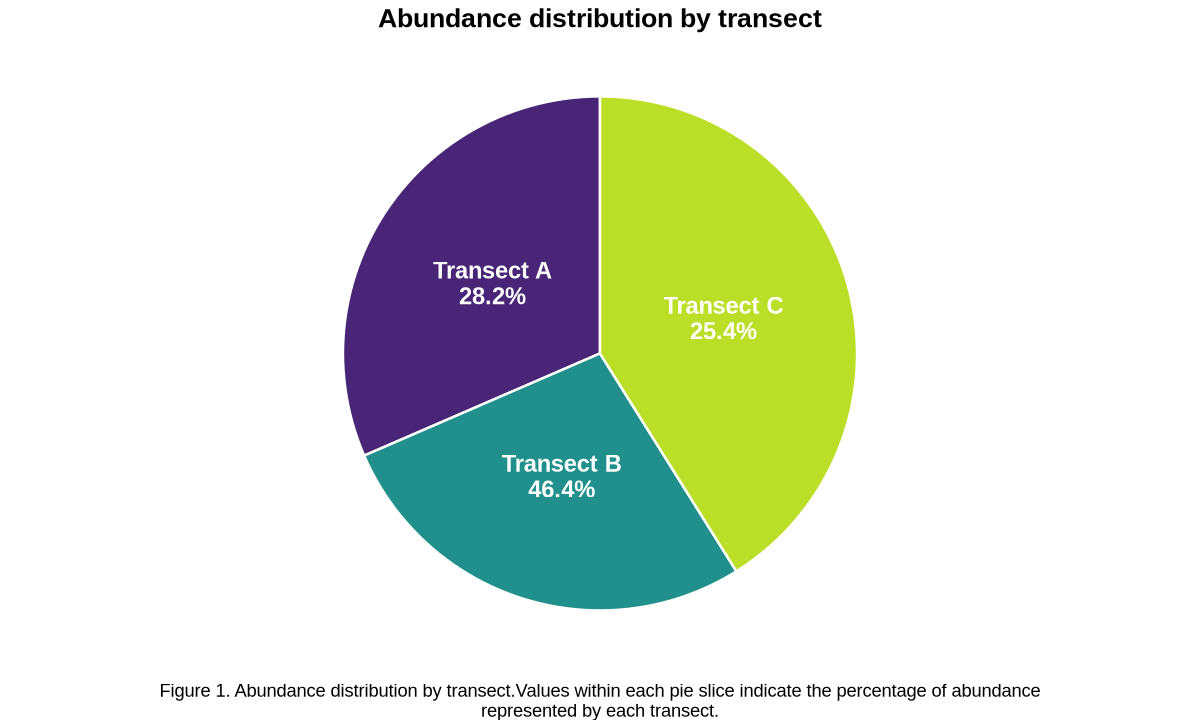

In [13]:
# Create a pie chart of the abundance distribution across transects
caption_text <- paste0(
    "Figure 1. Abundance distribution by transect.",
    "Values within each pie slice indicate the percentage of ",
    "abundance represented by each transect."
)

x.figure1 <- make_pie_chart(data_info, data_info$S.obs, data_info$Assemblage, data_info$label) +
    labs(
        title = "Abundance distribution by transect",
        caption = str_wrap(caption_text, width = 110)
    ) +
    theme(
        plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
        plot.caption = element_text(hjust = 0.5, size = 11),
        legend.position = "none"
    )

options(repr.plot.width = 10, repr.plot.height = 6)
x.figure1

#### Results
Table 1 summarizes the abundance and observed species richness of saproxylic fungal assemblages in Transects A, B, and C. Observed species richness varied among the three transects, with 23 species recorded in Transect A, 20 in Transect B, and 30 in Transect C. 

Figure 1 shows the distribution of saproxylic fungal abundance across Transects A, B, and C. Transect B accounted for the largest proportion of the total abundance at 46.4%, followed by Transect A at 28.2% and Transect C at 25.4%. 

**The distribution shows that fungal occurrences were unevenly distributed among the three transects, with nearly half of the total abundance recorded in Transect B.**

### 2.2. Observed and estimated diversity

In [14]:
# Asymptotic diversity estimates for Hill numbers (q = 0, 1, 2)
asy_est <- inext$AsyEst %>%
    mutate(
        `95% CI` = sprintf("%.2f – %.2f", LCL, UCL),
        Diversity_q = recode_values(
            Diversity,
            from = c("Species richness", "Shannon diversity", "Simpson diversity"),
            to = c("0", "1", "2"),
            default = Diversity
        )
    )

#### Table 2: Observed and asymptotic Hill diversity estimates

In [15]:
# Create a publish-ready table of the asymptotic Hill diversity estimates
caption_text <- paste0(
    "Table 2: Observed and asymptotic Hill diversity estimates for saproxylic fungal ",
    "assemblages across Transects A, B, and C. Reported values include observed diversity, ",
    "estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2."
)

x.table2 <- asy_est %>%
    mutate(
        # Calculate the Relative Standard Error
        rse = s.e./Estimator * 100
    ) %>%
    select (
        Assemblage,
        Diversity_q,
        Observed,
        Estimator,
        rse,
        `95% CI`,
    ) %>%
    gt() %>% 
    cols_label(
        Assemblage = md("**Transect**"),
        Diversity_q = md("**Diversity**"),
        Observed = md("**Observed**"),
        Estimator = md("**Asymptotic estimate**"),
        rse = md("**RSE**"),
        `95% CI` = md("**95% CI**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    cols_align(
        align = "right",
        columns = 5
    ) %>%
    fmt(
        columns = Diversity_q,
        fns = function(x) {
            recode_values(x,
                "0" ~ "Species richness (q=0)", 
                "1" ~ "Shannon diversity (q=1)", 
                "2" ~ "Simpson diversity (q=2)"
            )
        }
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    fmt_number(
        columns = rse,
        pattern = "{x}%"
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [16]:
x.table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 2: Observed and asymptotic Hill diversity estimates for saproxylic fungal assemblages across Transects A, B, and C. Reported values include observed diversity, estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Assemblage" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Diversity_q" align="center" bgcolor="#FFFFFF" valign="bottom"> Diversity 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Observed" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Estimator" align="center" bgcolor="#FFFFFF" valign="bottom"> Asymptotic estimate 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left

#### Results
Table 2 summarizes the observed and estimated asymptotic diversity of the saproxylic fungal assemblages across transects. Diversity was evaluated using Hill-number orders *q* = 0, *q* = 1, and *q* = 2, representing species richness, Shannon diversity, and Simpson diversity, respectively.

For species richness (_q = 0_), observed diversity varied among the three transects, with _23_ species recorded in Transect A, _20_ in Transect B, and _30_ in Transect C. **The corresponding asymptotic estimates were identical to the observed values for all three transect assemblages. This result is likely influenced by preprocessing of the dataset, particularly the removal of singleton and doubleton taxa, which reduces the rare-species information used to estimate undetected diversity.**

At _q = 1_, exponential Shannon diversity was _5.95_ for Transect A, _3.80_ for Transect B, and _8.54_ for Transect C. **Observed and asymptotic estimates were very similar across the three transects, although this convergence should be interpreted in the context of the prior filtering of rare taxa.**

At _q = 2_, inverse Simpson diversity was _4.00_ for Transect A, _2.73_ for Transect B, and _5.62_ for Transect C. **Observed and asymptotic estimates were nearly identical, indicating that little additional diversity attributable to common and dominant species was estimated beyond that represented in the observed assemblages.**

**The asymptotic diversity estimates across all three transects demonstrated high precision and low sampling uncertainty for species richness (q = 0), Shannon diversity (q = 1), and Simpson diversity (q = 2). The Relative Standard Error (RSE) for each of these mathematical indices remained consistently below the standard 10% threshold (range: 1.11% to 4.31%) for ecological indicators.**

Overall, diversity followed the consistent pattern **Transect C > Transect A > Transect B** across all three Hill-number orders (_q = 0, 1, and 2_).

### 2.3. Sample-size-based analysis (type = 1)

#### Figure 2: Sample-size-based analysis

In [17]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type = 1)

# Format variables
plot_data <- plot_data %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed/reference points BEFORE filtering
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Retain only rarefaction and extrapolation curves
plot_data <- plot_data %>%
    filter(Method %in% c("Rarefaction", "Extrapolation"))

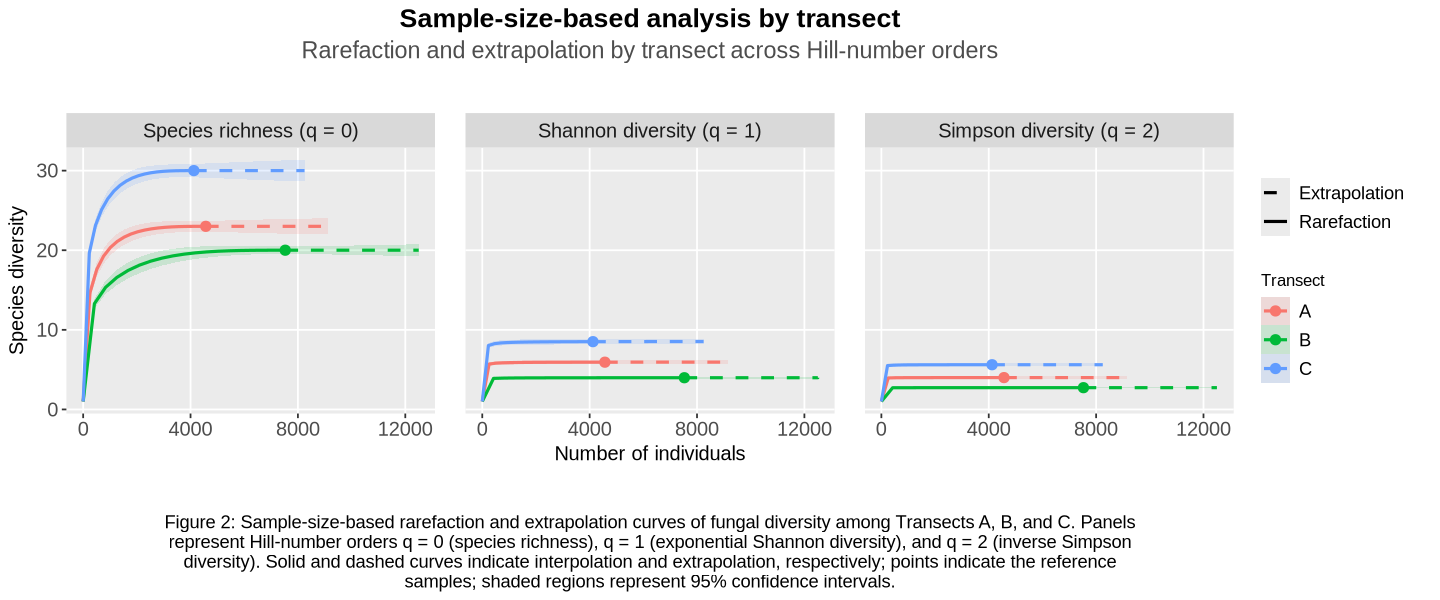

In [18]:
title_text <- paste0(
    "Sample-size-based analysis by transect"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation by transect across Hill-number orders"
)

caption_text <- paste0(
    "Figure 2: Sample-size-based rarefaction and extrapolation curves of fungal diversity among Transects A, B, and C. ",
    "Panels represent Hill-number orders q = 0 (species richness), q = 1 (exponential Shannon diversity), ",
    "and q = 2 (inverse Simpson diversity). Solid and dashed curves indicate interpolation and extrapolation, ",
    "respectively; points indicate the reference samples; shaded regions represent 95% confidence intervals."
)

x.figure2 <- ggplot(plot_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            fill = Transect
        )
    ) +
    geom_ribbon(
        aes(
            ymin = y.lwr,
            ymax = y.upr,
            group = interaction(Transect, Method)
        ),
        alpha = 0.15,
        linewidth = 0
    ) +
    geom_line(
        aes(linetype = Method, group = interaction(Transect, Method)),
        linewidth = 0.9
    ) +
    geom_point(
        data = observed_data,
        aes(x = x, y = y, color = Transect),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 12500), oob = squish) +
    facet_wrap(
        ~ Order.q,
        nrow = 1,
        scales = "fixed"
    ) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
        color = "Transect",
        fill = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 5)
x.figure2

#### Results
Figure 2 presents sample-size-based rarefaction and extrapolation curves comparing saproxylic fungal diversity among Transects A, B, and C separately for each Hill-number order. 

Diversity increased with sample size during the initial portion of sampling, after which the curves gradually flattened and approached a plateau with extended extrapolation. This pattern was evident across the three transects and diversity orders, indicating that **relatively little additional diversity was predicted with further increases in sample size.**

### 2.4. Sample completeness (type = 2)

#### Figure 3: Sample completeness

In [19]:
# Extract sample-completeness data
plot_data <- fortify(inext, type = 2)

# Format variables for transect-only analysis
plot_data <- plot_data %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C"))
    )

# Preserve observed/reference points BEFORE changing Method
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat the observed point as the endpoint of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

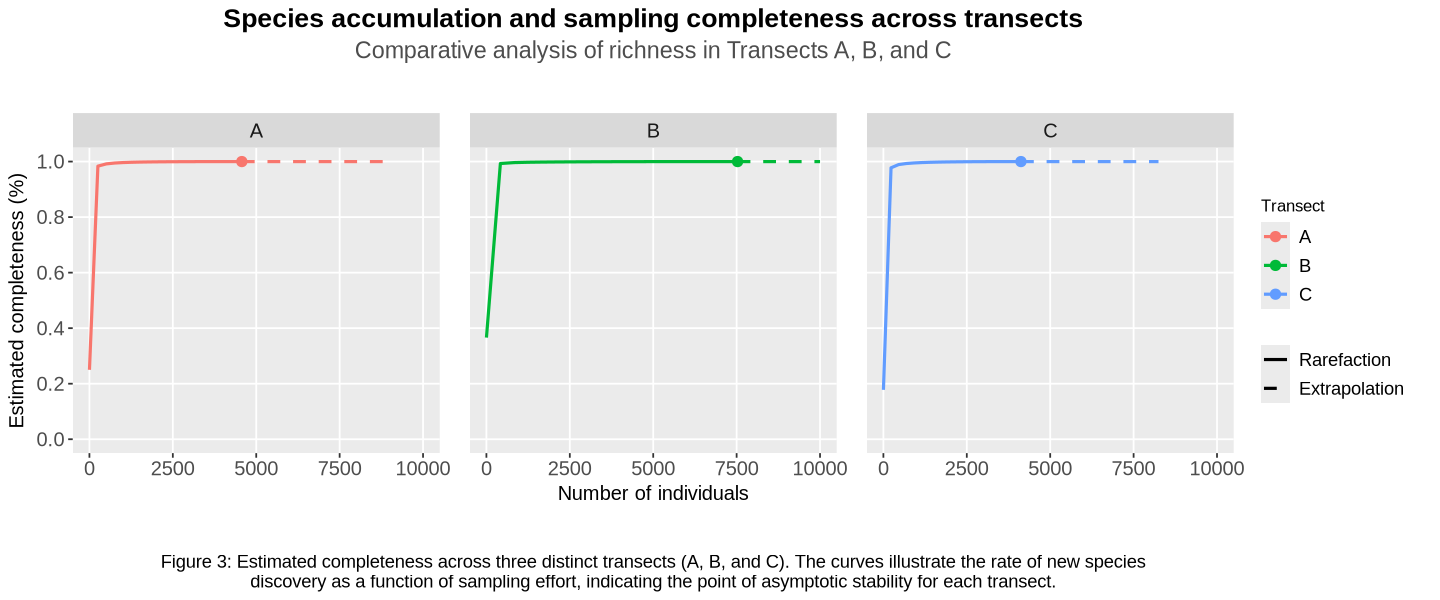

In [20]:
title_text <- paste0(
    "Species accumulation and sampling completeness across transects"
)

subtitle_text <- paste0(
    "Comparative analysis of richness in Transects A, B, and C"
)

caption_text <- paste0(
    "Figure 3: Estimated completeness across three distinct transects (A, B, and C). ",
    "The curves illustrate the rate of new species discovery as a function of sampling effort, ",
    "indicating the point of asymptotic stability for each transect."
)

x.figure3 <- ggplot(plot_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        )
    ) +
    geom_line(linewidth = 0.9) +
    # Observed/reference sample
    geom_point(
        data = observed_data,
        aes(x = x, y = y, color = Transect),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    facet_wrap(
        ~ Transect,
        nrow = 1
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 10000), oob = squish) +
    scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2)) +
    labs(
        x = "Number of individuals",
        y = "Estimated completeness (%)",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 5)
x.figure3

#### Results
Figure 3 presents sample completeness curves for the saproxylic fungal assemblages across Transects A, B, and C. **All curves rise steeply before plateauing, indicating that sampling reached saturation and the richness estimates have stabilized.**

### 2.5. Coverage-based analysis (type = 3)

#### Figure 4: Coverage-based analysis

In [21]:
# Use the actual coverage-based iNEXT estimates
plot_data <- inext$iNextEst$coverage_based

# Preserve observed/reference points BEFORE modifying Method
observed_data <- plot_data %>%
    filter(Method == "Observed") %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Prepare transect-only plotting data
plot_data <- plot_data %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        ),
        # Treat observed estimate as the endpoint
        # of the rarefaction curve
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

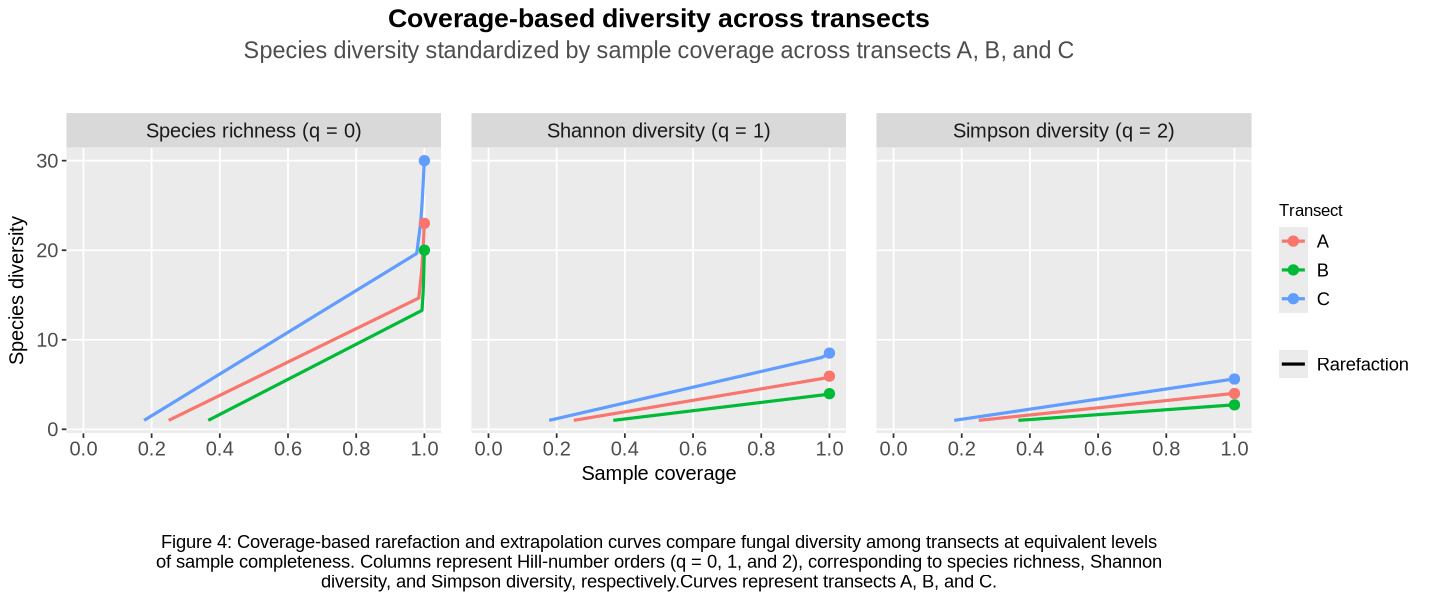

In [22]:
title_text <- paste0(
    "Coverage-based diversity across transects"
)

subtitle_text <- paste0(
    "Species diversity standardized by sample coverage across transects A, B, and C"
)

caption_text <- paste0(
    "Figure 4: Coverage-based rarefaction and extrapolation curves compare fungal diversity among transects ",
    "at equivalent levels of sample completeness. Columns represent Hill-number orders (q = 0, 1, and 2), ",
    "corresponding to species richness, Shannon diversity, and Simpson diversity, respectively.",
    "Curves represent transects A, B, and C."
)

x.figure4 <- ggplot(plot_data,
        aes(
            x = SC,
            y = qD,
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        )
    ) +
    geom_line(linewidth = 0.9) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    # Shared y-axis across Hill-number panels
    facet_wrap(
        ~ Order.q,
        nrow = 1,
        scales = "fixed"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2)) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 5)
x.figure4

#### Results
Figure 4 presents the coverage-based diversity curves organized by Hill-number order, allowing direct comparison of Transects A, B, and C at equivalent levels of sample coverage.

Across all three Hill-number orders, Transect C consistently exhibited the highest diversity, followed by Transect A and Transect B. This ranking was maintained for species richness (_q = 0_), exponential Shannon diversity (_q = 1_), and inverse Simpson diversity (_q = 2_). The persistence of the same ordering as progressively greater weight was placed on common and dominant taxa indicates that the higher diversity of Transect C was not restricted to rare species, but was also evident in the abundance structure of the assemblage.

Importantly, because Figure 4 expresses diversity relative to sample coverage, the persistence of the pattern **Transect C > Transect A > Transect B** indicates that the observed ranking is maintained when the transects are compared at equivalent levels of sampling completeness. Thus, the differences among transects are unlikely to be attributable solely to unequal sampling completeness.

## 3. Diversity by Transect and Wood Texture

In [23]:
# Create the abundance list based on transects and wood textures
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Texture, saproxylic_community_df)
names(saproxylic_df)[1:2] =  c("Transect", "Wood.Texture")         # Environment columns as Site
saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Texture) %>%
    summarise(
        across(3:last_col(), sum),                                 # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,"-",Wood.Texture, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Texture)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names

In [24]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])

In [25]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
#   q=0 for species richness, 
#   q=1 for Shannon diversity, and 
#   q=2 for Simpson diversity
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### 3.1. Abundance, species richness, and sample coverage

In [26]:
# Get iNEXT data summary
data_info <- inext$DataInfo %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Texture"),
        cols_remove = FALSE
    ) %>%
    mutate(
        Description = recode_values(
            Transect,
            from = c("A", "B", "C"),
            to = c("conifer forest with access of reindeer", 
                   "conifer forest without access of reindeer", 
                   "broadleaf forest and accessed to tourists"),
            default = Transect
        ),
        Sample_Coverage = paste0(SC * 100, "%")
    ) %>%
    select(
        Assemblage,
        Transect,
        Description,
        Wood.Texture,
        n,
        S.obs,
        Sample_Coverage
    )

#### Table 3: Abundance and observed species richness

In [27]:
# Create a publish-ready table of the summary data
caption_text <- paste0(
    "Table 3: Abundance, observed species richness, and sample coverage ",
    "by transect and wood texture."
)

y.table1 <- data_info %>%
    select (
        Transect,
        Description,
        Wood.Texture,
        n,
        S.obs,
        Sample_Coverage
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Description = md("**Description**"),
        Wood.Texture = md("**Wood Texture**"),
        n = md("**Abundance**"),
        S.obs = md("**Observed Richness**"),
        Sample_Coverage = md("**Sample Coverage**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [28]:
y.table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 3: Abundance, observed species richness, and sample coverage by transect and wood texture. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Texture" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Texture 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Abundance 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-num

#### Figure 5: Abundance distribution

In [29]:
a_data_info <- data_info %>%
    filter(Transect == "A") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Texture, "\n(", round(percentage, 1), "%)")
    )

In [30]:
b_data_info <- data_info %>%
    filter(Transect == "B") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Texture, "\n(", round(percentage, 1), "%)")
    )

In [31]:
c_data_info <- data_info %>%
    filter(Transect == "C") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Texture, "\n(", round(percentage, 1), "%)")
    )

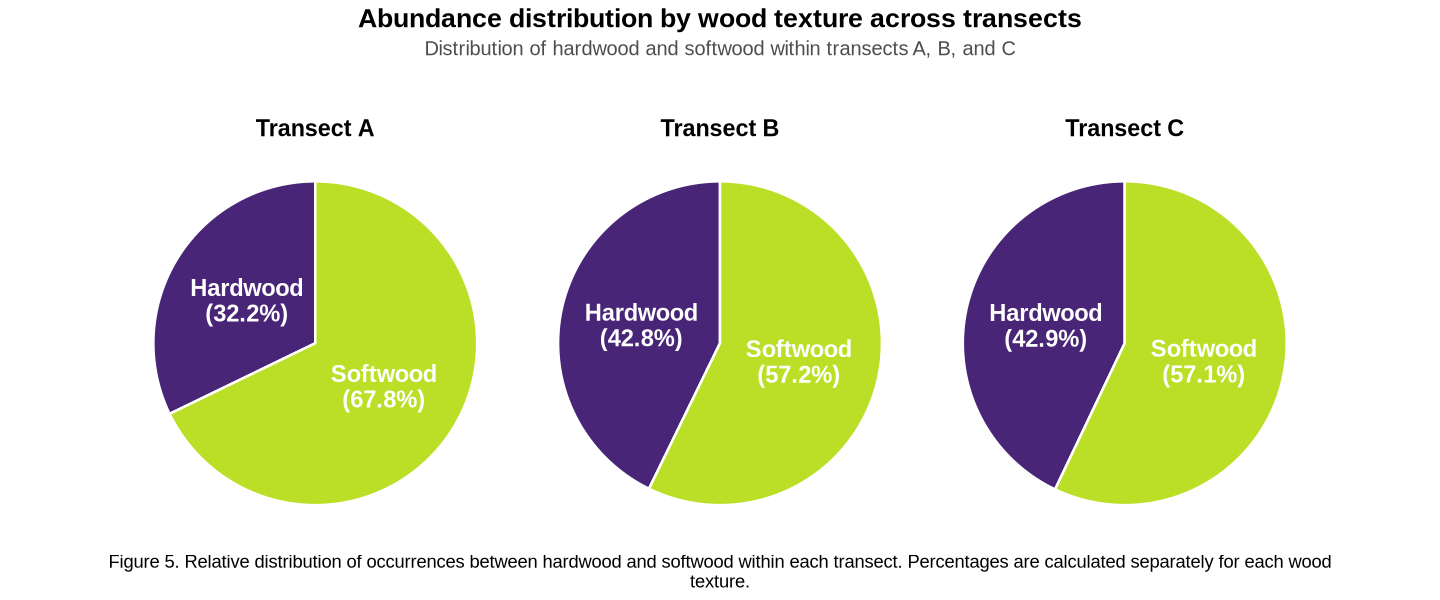

In [32]:
a_pie_chart <- make_pie_chart(a_data_info, a_data_info$percentage, a_data_info$Wood.Texture, a_data_info$label) +
    labs(title = "Transect A") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

b_pie_chart <- make_pie_chart(b_data_info, b_data_info$percentage, b_data_info$Wood.Texture, b_data_info$label) +
    labs(title = "Transect B") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

c_pie_chart <- make_pie_chart(c_data_info, c_data_info$percentage, c_data_info$Wood.Texture, c_data_info$label) +
    labs(title = "Transect C") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

caption_text <- paste0(
    "Figure 5. Relative distribution of occurrences between hardwood and softwood ",
    "within each transect. Percentages are calculated separately for each wood texture."
)

title_and_caption <- plot_annotation(
    title = "Abundance distribution by wood texture across transects",
    subtitle = "Distribution of hardwood and softwood within transects A, B, and C",
    caption = str_wrap(caption_text, width = 150),
    theme = theme(
        plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5, size = 12, color = "grey30", margin = margin(b=30)),
        plot.caption = element_text(hjust = 0.5, size = 11)
    )
)

combined_pie_chart <-
    a_pie_chart + b_pie_chart + c_pie_chart + title_and_caption    

y.figure1 <- combined_pie_chart
y.figure1

#### Results
Species richness varied by wood texture across all transects (Table 3). Specifically, **species counts were higher on softwood than hardwood** in each instance: Transect A (18 hardwood; 22 softwood), Transect B (14 hardwood; 20 softwood), and Transect C (22 hardwood; 26 softwood). 

A similar pattern was observed in fungal abundance (Figure 5), where softwood consistently supported a higher proportion of the community (57.1%–67.8%) relative to hardwood (32.2%–42.9%).

### 3.2. Observed and estimated diversity

In [33]:
asy_est <- inext$AsyEst %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Texture"),
        cols_remove = FALSE
    ) %>%
    mutate(
        `95% CI` = sprintf("%.2f – %.2f", LCL, UCL),
        Diversity_q = recode_values(
            Diversity,
            from = c("Species richness", "Shannon diversity", "Simpson diversity"),
            to = c("0", "1", "2"),
            default = Diversity
        )
    ) 

#### Table 4: Observed and asymptotic Hill diversity estimates

In [34]:
# Create a publish-ready table of the asymptotic Hill diversity estimates
caption_text <- paste0(
    "Table 4: Observed and asymptotic Hill diversity estimates for saproxylic fungal ",
    "assemblages across Transects A, B, and C and wood textures. Reported values ",
    "include observed diversity, estimated asymptotic diversity, and 95% confidence ",
    "intervals for q = 0, 1, and 2."
)

y.table2 <- asy_est %>%
    mutate(
        # Calculate the Relative Standard Error
        rse = s.e./Estimator * 100
    ) %>%
    select (
        Transect,
        Wood.Texture,
        Diversity_q,
        Observed,
        Estimator,
        rse,
        `95% CI`,
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Wood.Texture = md("**Wood Texture**"),
        Diversity_q = md("**Diversity**"),
        Observed = md("**Observed**"),
        Estimator = md("**Asymptotic estimate**"),
        rse = md("**RSE**"),
        `95% CI` = md("**95% CI**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    cols_align(
        align = "right",
        columns = 5
    ) %>%
    fmt(
        columns = Diversity_q,
        fns = function(x) {
            recode_values(x,
                "0" ~ "Species richness (q=0)", 
                "1" ~ "Shannon diversity (q=1)", 
                "2" ~ "Simpson diversity (q=2)"
            )
        }
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    fmt_number(
        columns = rse,
        pattern = "{x}%"
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [35]:
y.table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 4: Observed and asymptotic Hill diversity estimates for saproxylic fungal assemblages across Transects A, B, and C and wood textures. Reported values include observed diversity, estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Texture" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Texture 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Diversity_q" align="center" bgcolor="#FFFFFF" valign="bottom"> Diversity 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Observed" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-r

#### Results
Table 4 summarizes the observed and estimated asymptotic diversity of the saproxylic fungal assemblages across wood textures (hardwood and softwood) in transects A, B, and C.

For species richness (_q = 0_), observed diversity ranged from 18.00 to 23.33 for hardwood assemblages and from 20.00 to 34.50 for softwood assemblages for all three transects. 

At _q = 1_, exponential Shannon diversity ranged from 3.09 to 5.89 for hardwood assemblages and from 4.40 to 5.34 for softwood assemblages across the three transects, indicating greater variation in diversity among the hardwood assemblages.

At _q = 2_, inverse Simpson diversity ranged from 2.18 to 3.68 for hardwood assemblages and from 3.11 to 3.96 for softwood assemblages across the three transects, indicating a wider range of diversity values among the hardwood assemblages.

**The asymptotic diversity estimates for softwood assemblages in transect A and hardwood assemblages in transects B and C yielded RSEs exceeding 29% (31.24%, 29.17%, and 32.15%, respectively), indicating potentially unreliable data due to small sample sizes. In contrast, all other assemblage estimates across the remaining transects demonstrated high precision, with RSE values ranging from 1.83% to 9.14%.**

### 3.3. Sample-size-based analysis (type = 1)

#### Figure 6: Sample-size-based analysis

In [36]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type = 1)

# Split Assemblage into Transect and Wood Texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Texture"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Texture = factor(Wood.Texture, levels = c("Hardwood", "Softwood")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed/reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat observed as the endpoint of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method,levels = c("Rarefaction", "Extrapolation"))
    )

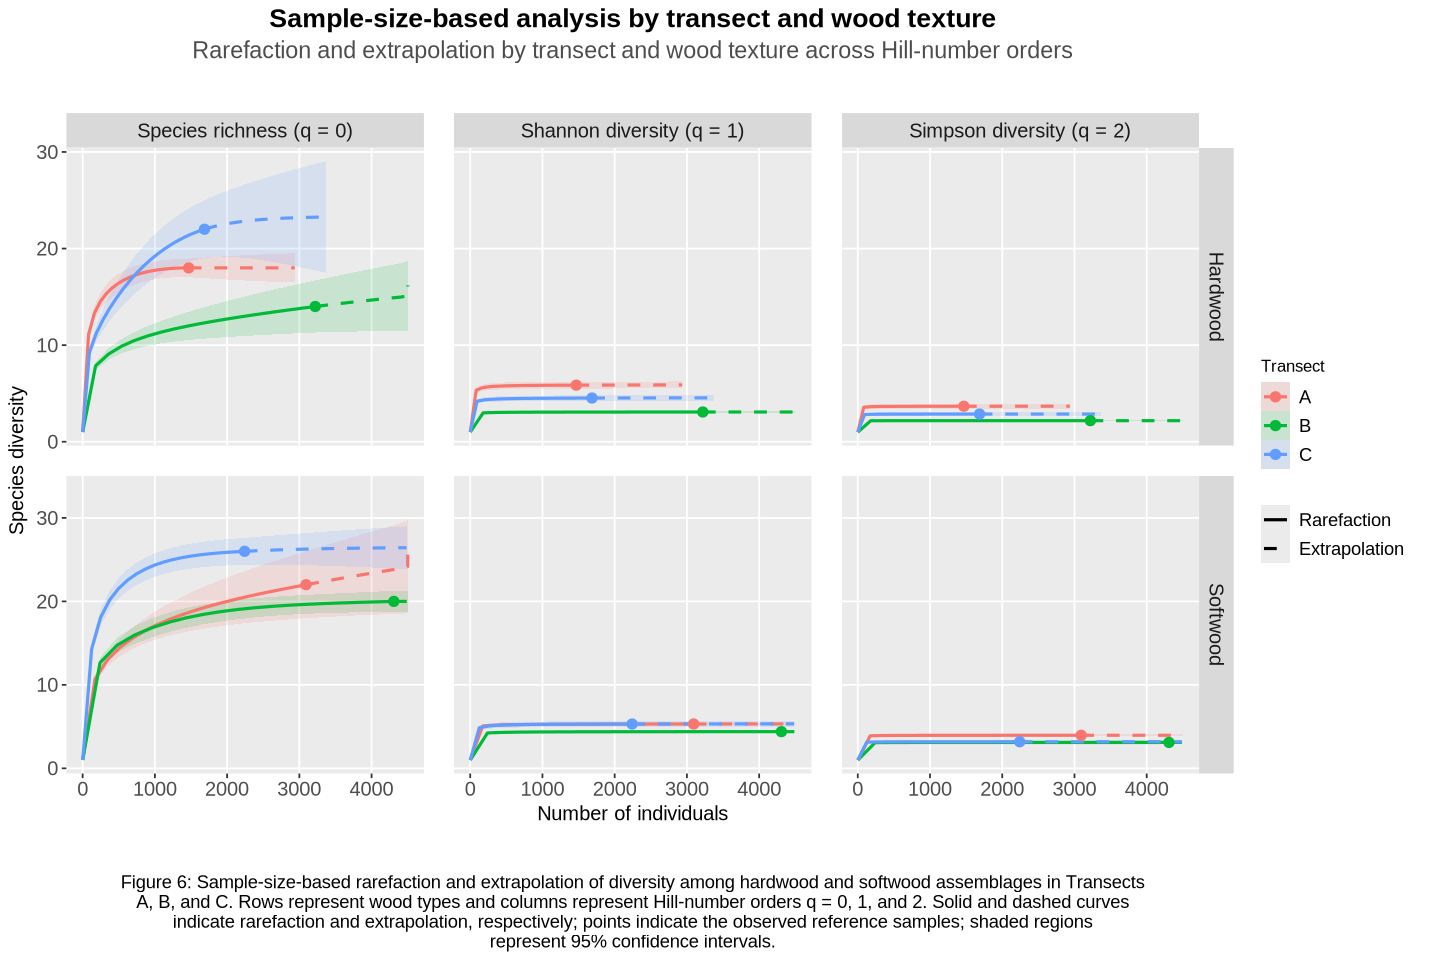

In [37]:
title_text <- paste0(
    "Sample-size-based analysis by transect and wood texture"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation by transect and wood texture across Hill-number orders"
)

caption_text <- paste0(
    "Figure 6: Sample-size-based rarefaction and extrapolation of diversity among hardwood and softwood assemblages ",
    "in Transects A, B, and C. Rows represent wood types and columns represent Hill-number orders q = 0, 1, and 2. ",
    "Solid and dashed curves indicate rarefaction and extrapolation, respectively; points indicate the observed ",
    "reference samples; shaded regions represent 95% confidence intervals."
)

y.figure2 <- ggplot(plot_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            fill = Transect
        )
    ) +
    geom_ribbon(
        aes(
            ymin = y.lwr,
            ymax = y.upr,
            group = interaction(Transect, Method)
        ),
        alpha = 0.15,
        linewidth = 0
    ) +
    geom_line(
        aes(
            linetype = Method,
            group = interaction(Transect, Method)
        ),
        linewidth = 0.9
    ) +
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
scale_x_continuous(limits = c(0, 4500), oob = squish) +
    facet_grid(
        Wood.Texture ~ Order.q,
        scales = "free_y"
    ) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
        color = "Transect",
        fill = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
y.figure2

#### Results
Figure 6 displays sample-size-based rarefaction and extrapolation curves comparing saproxylic fungal diversity between hardwood and softwood assemblages across Transects A, B, and C, organized by Hill number order. Across most assemblages and diversity orders, diversity increased with sampling effort and gradually approached an asymptote during extrapolation. 

**For species richness (_q = 0_), both hardwood and softwood assemblages followed the consistent pattern Transect C > Transect A > Transect B.** 
* The hardwood assemblage in Transect A had largely reached a plateau, whereas the softwood assemblages in Transects B and C were approaching a plateau.
* In contrast, **the hardwood assemblages in Transects B and C and the softwood assemblage in Transect A retained upward trajectories during extrapolation, indicating greater potential for additional species to be detected with increased sampling effort.**
* **The confidence intervals widened with increasing extrapolated sample size for the hardwood assemblages in Transects B and C and the softwood assemblages in Transects A and C, indicating increasing uncertainty in the corresponding species-richness estimates farther beyond the observed sample sizes.**

**Hardwood assemblages showed the same ranking for both Shannon (q = 1) and Simpson (q = 2) diversity: Transect A > Transect C > Transect B.** These curves were largely asymptotic, indicating relatively stable estimates of diversity when greater weight was assigned to common (q = 1) and dominant (q = 2) species. 

In contrast, **Shannon and Simpson diversity of softwood assemblages were relatively similar among the three transects**, with the corresponding curves also approaching or reaching plateaus.

### 3.4. Sample completeness (type = 2)

#### Figure 7: Sample completeness

In [38]:
# Extract sample-completeness data
plot_data <- fortify(inext, type = 2)

# Separate assemblage into transect and wood texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Texture"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Texture = factor(Wood.Texture, levels = c("Hardwood", "Softwood"))
    )

# Preserve the observed reference points before converting "Observed" to "Rarefaction"
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat the observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

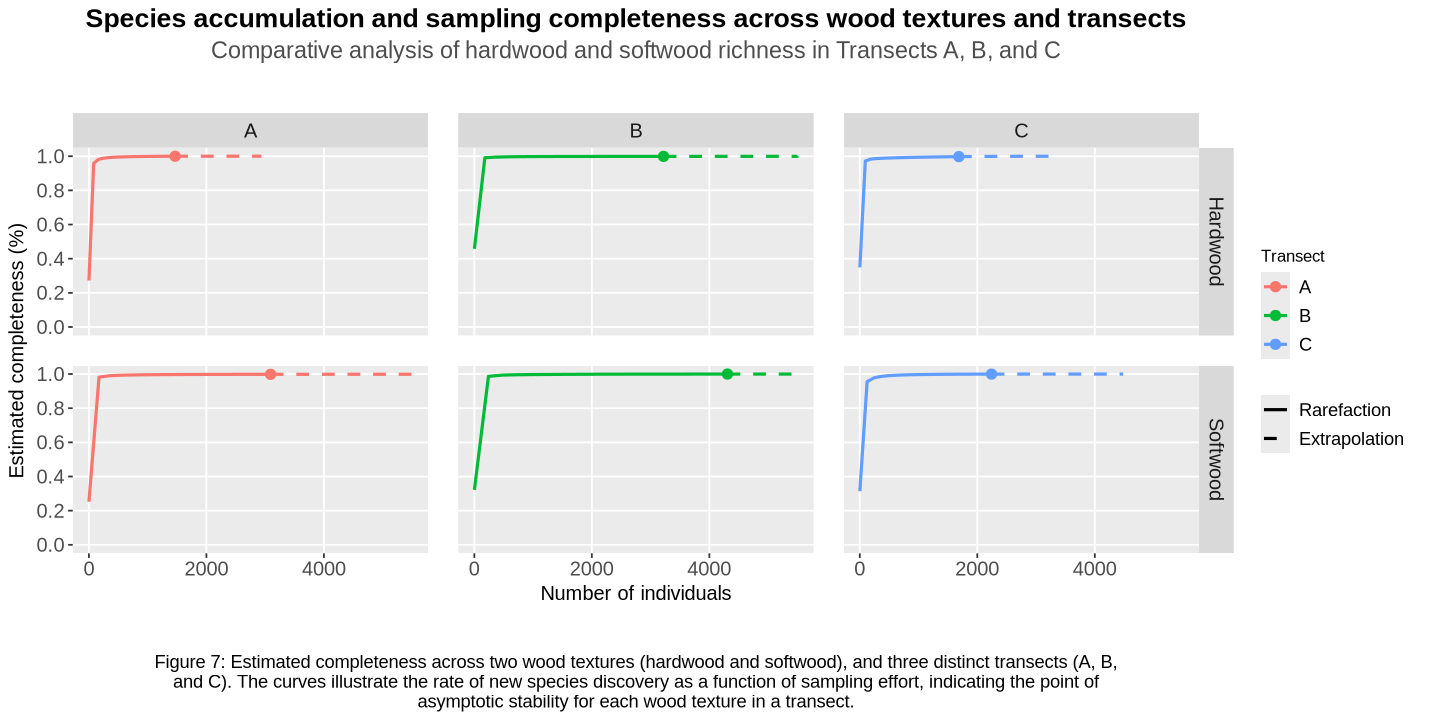

In [39]:
title_text <- paste0(
    "Species accumulation and sampling completeness across wood textures and transects"
)

subtitle_text <- paste0(
    "Comparative analysis of hardwood and softwood richness in Transects A, B, and C"
)

caption_text <- paste0(
    "Figure 7: Estimated completeness across two wood textures (hardwood and softwood), and ",
    "three distinct transects (A, B, and C). ",
    "The curves illustrate the rate of new species discovery as a function of sampling effort, ",
    "indicating the point of asymptotic stability for each wood texture in a transect."
)

y.figure3 <- ggplot(plot_data,
    aes(
        x = x,
        y = y,
        color = Transect,
        linetype = Method
    )) +
    geom_line(linewidth = 0.9) +
    # Observed/reference sample
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    # Top row = Hardwood
    # Bottom row = Softwood
    # Columns = Transects A, B, C
    facet_grid(
        Wood.Texture ~ Transect
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 5500), oob = squish) +
    scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2)) +
    labs(
        x = "Number of individuals",
        y = "Estimated completeness (%)",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 6)
y.figure3

#### Results
Figure 7 illustrates the sample completeness curves for saproxylic fungal assemblages across wood textures (hardwood and softwood) and Transects A, B, and C. **The curves exhibit rapid initial accumulation followed by asymptotic behavior, suggesting that sampling effort was sufficient to capture a representative portion of species richness and that richness estimates have stabilized.**

### 3.5. Coverage-based analysis (type = 3)

#### Figure 8: Coverage-based analysis

In [40]:
# Use the actual coverage-based iNEXT estimates
plot_data <- inext$iNextEst$coverage_based

# Split Assemblage into Transect and Wood Texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Texture"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Texture = factor(Wood.Texture, levels = c("Hardwood", "Softwood")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve observed/reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

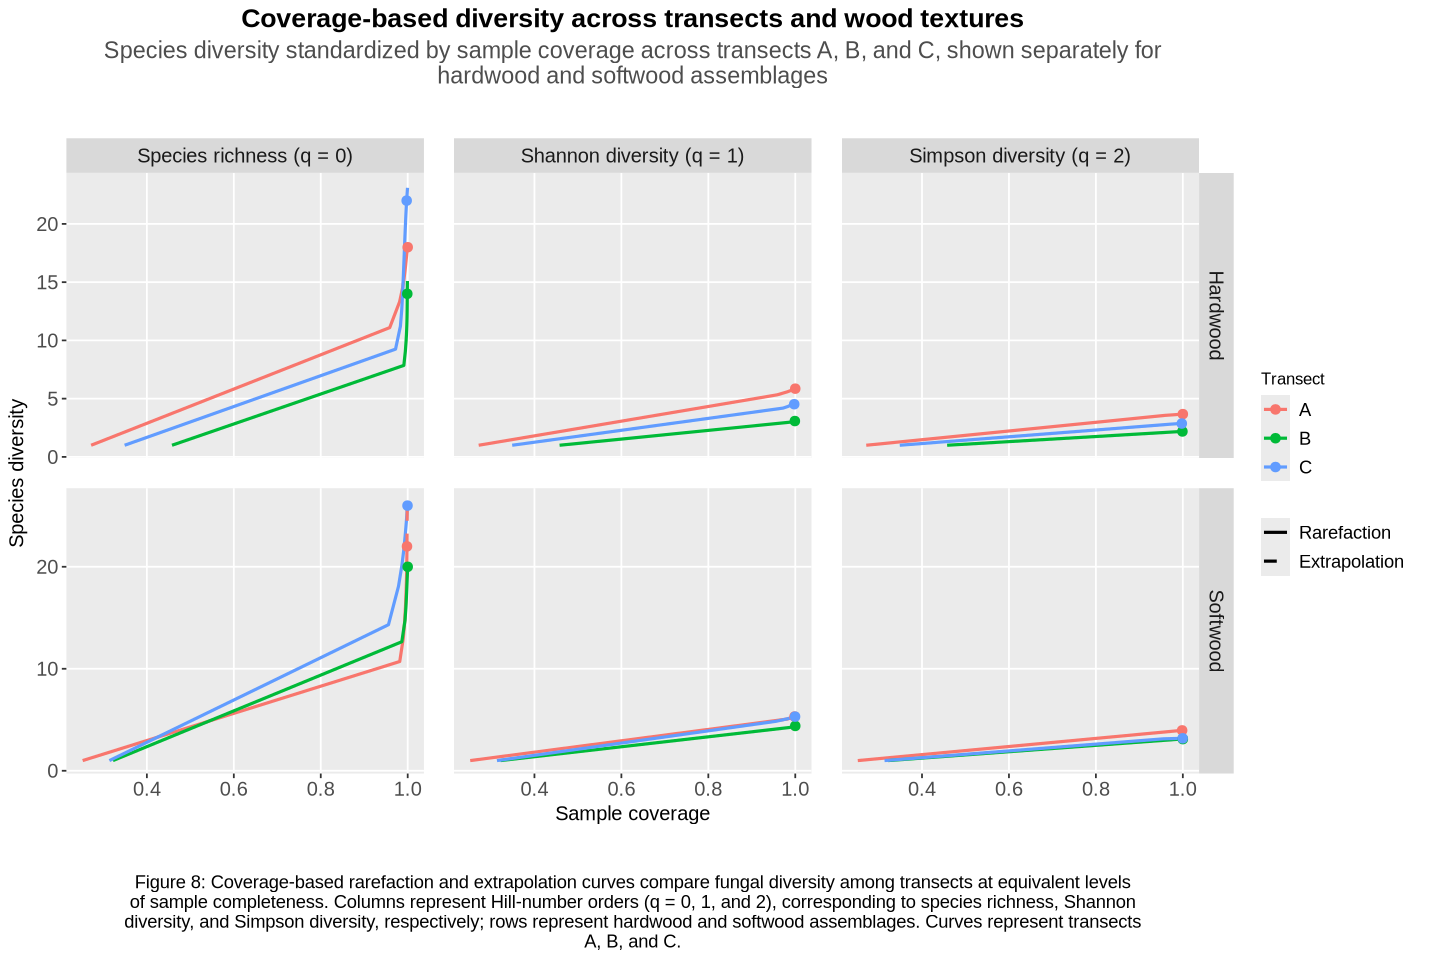

In [41]:
title_text <- paste0(
    "Coverage-based diversity across transects and wood textures"
)

subtitle_text <- paste0(
    "Species diversity standardized by sample coverage across transects A, B, and C, shown separately for hardwood and softwood assemblages"
)

caption_text <- paste0(
    "Figure 8: Coverage-based rarefaction and extrapolation curves compare fungal diversity among transects ",
    "at equivalent levels of sample completeness. Columns represent Hill-number orders (q = 0, 1, and 2), ",
    "corresponding to species richness, Shannon diversity, and Simpson diversity, respectively; ",
    "rows represent hardwood and softwood assemblages. Curves represent transects A, B, and C."
)

y.figure4 <- ggplot(plot_data, aes(x = SC, y = qD)) +
    # Coverage-based diversity curves
    geom_line(
        aes(
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top, Softwood on bottom
    # Hill numbers across columns
    facet_grid(
        Wood.Texture ~ Order.q,
        scales = "free_y"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
y.figure4

#### Results
Figure 8 presents coverage-based diversity curves organized by Hill number order, enabling direct comparison of hardwood and softwood assemblages across Transects A, B, and C at equivalent levels of sample coverage.

**For species richness (q = 0), both hardwood and softwood assemblages followed the same pattern, with diversity highest in Transect C, followed by Transect A and then Transect B.**

**For hardwood assemblages, Shannon (q = 1) and Simpson (q = 2) diversity followed the descending order Transect A > Transect C > Transect B. In contrast, Shannon and Simpson diversity of softwood assemblages were relatively similar across the three transects.**

## 4. Diversity by Transect and Wood Type

In [42]:
# Create the abundance list based on transects and wood types
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Type, saproxylic_community_df)
names(saproxylic_df)[1:2] =  c("Transect", "Wood.Type")         # Environment columns as Site
saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Type) %>%
    summarise(
        across(3:last_col(), sum),                              # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,"-",Wood.Type, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Type)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names

In [43]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])

In [44]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
#   q=0 for species richness, 
#   q=1 for Shannon diversity, and 
#   q=2 for Simpson diversity
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### 4.1. Abundance, observed richness, and sample coverage

In [45]:
# Get iNEXT data summary
data_info <- inext$DataInfo %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Type"),
        cols_remove = FALSE
    ) %>%
    mutate(
        Description = recode_values(
            Transect,
            from = c("A", "B", "C"),
            to = c("conifer forest with access of reindeer", 
                   "conifer forest without access of reindeer", 
                   "broadleaf forest and accessed to tourists"),
            default = Transect
        ),
        Sample_Coverage = paste0(SC * 100, "%")
    ) %>%
    select(
        Assemblage,
        Transect,
        Description,
        Wood.Type,
        n,
        S.obs,
        Sample_Coverage
    )

#### Table 5: Abundance and observed species richness

In [46]:
# Create a publish-ready table of the summary data
caption_text <- paste0(
    "Table 5: Abundance, observed species richness, and sample coverage ",
    "by transect and wood type."
)

z.table1 <- data_info %>%
    select (
        Transect,
        Description,
        Wood.Type,
        n,
        S.obs,
        Sample_Coverage
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Description = md("**Description**"),
        Wood.Type = md("**Wood Type**"),
        n = md("**Abundance**"),
        S.obs = md("**Observed Richness**"),
        Sample_Coverage = md("**Sample Coverage**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [47]:
z.table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 5: Abundance, observed species richness, and sample coverage by transect and wood type. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Type" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Type 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Abundance 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tab

#### Figure 9: Abundance distribution

In [48]:
a_data_info <- data_info %>%
    filter(Transect == "A") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Type, "\n(", round(percentage, 1), "%)")
    )

In [49]:
b_data_info <- data_info %>%
    filter(Transect == "B") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Type, "\n(", round(percentage, 1), "%)")
    )

In [50]:
c_data_info <- data_info %>%
    filter(Transect == "C") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Type, "\n(", round(percentage, 1), "%)")
    )

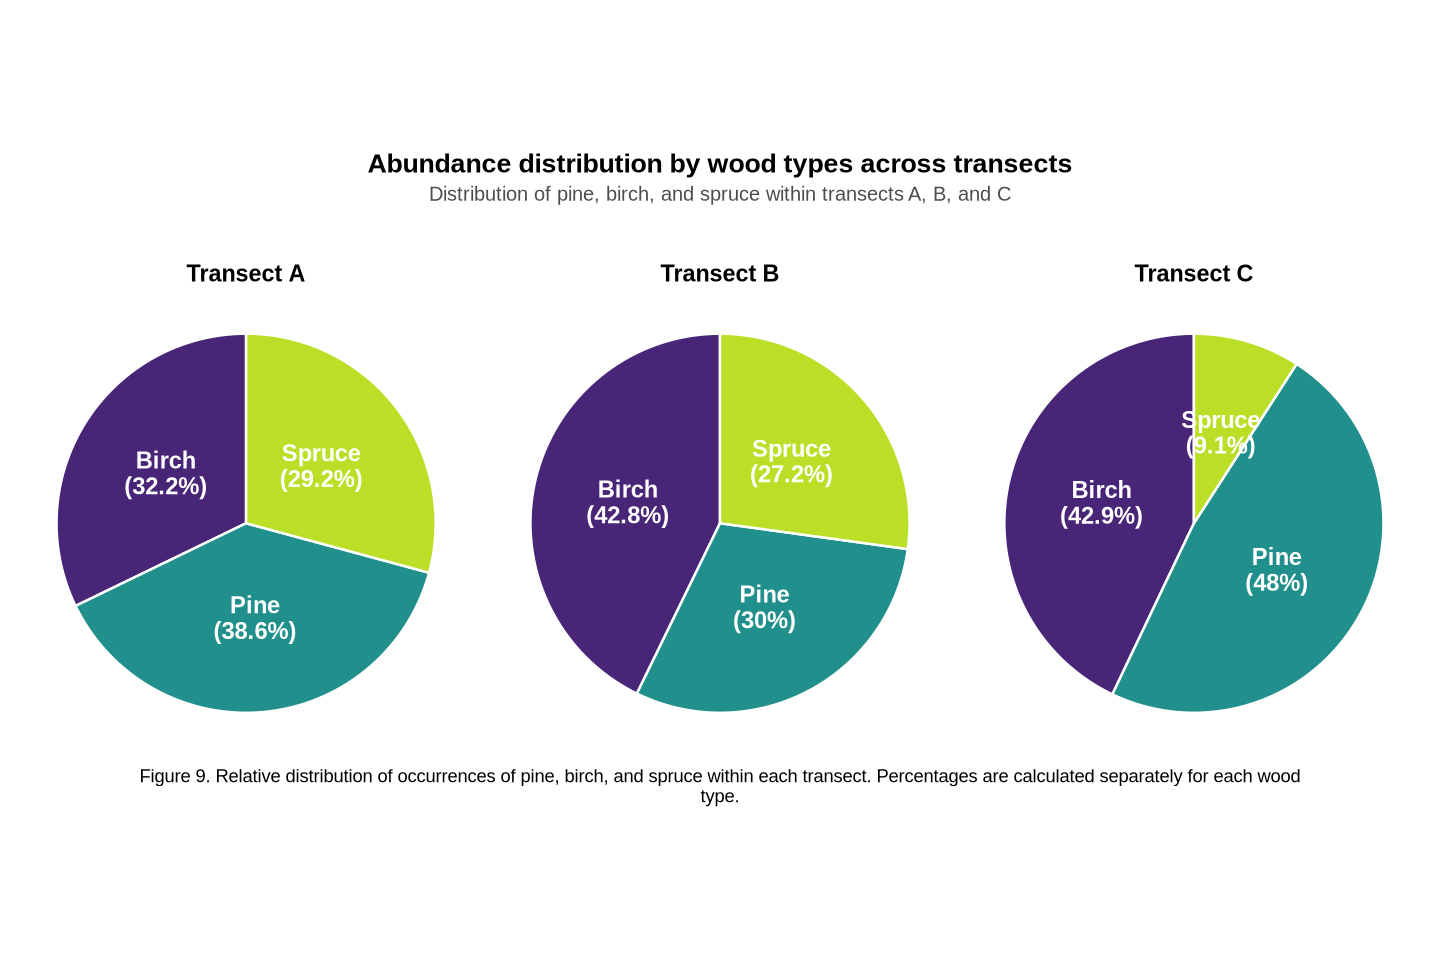

In [51]:
# How does wood-texture composition differ within each transect?
a_pie_chart <- make_pie_chart(a_data_info, a_data_info$percentage, a_data_info$Wood.Type, a_data_info$label) +
    labs(title = "Transect A") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

b_pie_chart <- make_pie_chart(b_data_info, b_data_info$percentage, b_data_info$Wood.Type, b_data_info$label) +
    labs(title = "Transect B") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

c_pie_chart <- make_pie_chart(c_data_info, c_data_info$percentage, c_data_info$Wood.Type, c_data_info$label) +
    labs(title = "Transect C") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

caption_text <- paste0(
    "Figure 9. Relative distribution of occurrences of pine, birch, and spruce ",
    "within each transect. Percentages are calculated separately for each wood type."
)

title_and_caption <- plot_annotation(
    title = "Abundance distribution by wood types across transects",
    subtitle = "Distribution of pine, birch, and spruce within transects A, B, and C",
    caption = str_wrap(caption_text, width = 150),
    theme = theme(
        plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5, size = 12, color = "grey30", margin = margin(b=30)),
        plot.caption = element_text(hjust = 0.5, size = 11)
    )
)

combined_pie_chart <-
    a_pie_chart + b_pie_chart + c_pie_chart + title_and_caption    

z.figure1 <- combined_pie_chart
z.figure1

#### Results
Species richness varied by wood type across all transects (Table 5). In Transect A, richness was consistent across pine, birch, and spruce (17, 18, and 17, respectively), whereas Transect B showed a decline in birch (14) compared to pine (16) and spruce (17). Transect C exhibited the highest overall richness, particularly for pine and birch (22 each).

Fungal abundance distributions followed a distinct pattern (Figure 9). While Transect A showed a relatively even distribution among wood types, Transect B was dominated by birch (42.8%). Most notably, Transect C displayed high abundance for pine (48%) and birch (42.8%), but a significant reduction in spruce abundance (9.1%).

### 4.2. Observed and estimated diversity

In [52]:
asy_est <- inext$AsyEst %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Types"),
        cols_remove = FALSE
    ) %>%
    mutate(
        `95% CI` = sprintf("%.2f – %.2f", LCL, UCL),
        Diversity_q = recode_values(
            Diversity,
            from = c("Species richness", "Shannon diversity", "Simpson diversity"),
            to = c("0", "1", "2"),
            default = Diversity
        )
    ) 

#### Table 6: Observed and asymptotic Hill diversity estimates

In [53]:
# Create a publish-ready table of the asymptotic Hill diversity estimates
caption_text <- paste0(
    "Table 6: Observed and asymptotic Hill diversity estimates for saproxylic fungal ",
    "assemblages across Transects A, B, and C and wood types Reported values ",
    "include observed diversity, estimated asymptotic diversity, and 95% confidence ",
    "intervals for q = 0, 1, and 2."
)

z.table2 <- asy_est %>%
    mutate(
        # Calculate the Relative Standard Error
        rse = s.e./Estimator * 100
    ) %>%
    select (
        Transect,
        Wood.Types,
        Diversity_q,
        Observed,
        Estimator,
        rse,
        `95% CI`,
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Wood.Types = md("**Wood Types**"),
        Diversity_q = md("**Diversity**"),
        Observed = md("**Observed**"),
        Estimator = md("**Asymptotic estimate**"),
        rse = md("**RSE**"),
        `95% CI` = md("**95% CI**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    cols_align(
        align = "right",
        columns = 5
    ) %>%
    fmt(
        columns = Diversity_q,
        fns = function(x) {
            recode_values(x,
                "0" ~ "Species richness (q=0)", 
                "1" ~ "Shannon diversity (q=1)", 
                "2" ~ "Simpson diversity (q=2)"
            )
        }
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    fmt_number(
        columns = rse,
        pattern = "{x}%"
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [54]:
z.table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 6: Observed and asymptotic Hill diversity estimates for saproxylic fungal assemblages across Transects A, B, and C and wood types Reported values include observed diversity, estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Types" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Types 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Diversity_q" align="center" bgcolor="#FFFFFF" valign="bottom"> Diversity 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Observed" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-sty

#### Results
Table 6 summarizes the observed and estimated asymptotic diversity of saproxylic fungal assemblages associated with pine, birch, and spruce across Transects A, B, and C.

**For species richness (q = 0)**, diversity ranged from 16.50 to 22.25 for pine assemblages, from 18.00 to 23.33 for birch assemblages, and from 17.17 to 23.00 for spruce assemblages across the three transects. **The ranges were similar among wood types, indicating comparable variation in species richness among transects.**

At q = 1, exponential Shannon diversity ranged from 3.66 to 4.69 for pine assemblages, from 3.09 to 5.89 for birch assemblages, and from 3.00 to 8.49 for spruce assemblages across the three transects. **Spruce assemblages exhibited substantially greater variation in Shannon diversity among transects than birch or pine assemblages, whereas pine assemblages showed the least variation.**

At q = 2, inverse Simpson diversity ranged from 2.76 to 3.19 for pine assemblages, from 2.18 to 3.68 for birch assemblages, and from 3.11 to 3.96 for spruce assemblages across the three transects. **Birch assemblages exhibited the greatest variation in inverse Simpson diversity, whereas pine assemblages showed the least variation. Spruce assemblages showed comparatively higher and more consistent inverse Simpson diversity across transects.**

Relative standard error (RSE) varied considerably among diversity orders and transect–wood combinations. The largest RSE values occurred for asymptotic species richness (q = 0), particularly for birch in Transect C (38.13%), pine in Transect A (29.29%), birch in Transect B (25.93%), spruce in Transect C (24.01%), and spruce in Transect A (23.39%). Lower, but still comparatively elevated, RSE values were observed for spruce in Transect B (15.08%) and pine in Transects B (12.03%) and C (11.15%).

In contrast, the remaining asymptotic diversity estimates across pine, birch, and spruce assemblages had substantially lower RSE values, ranging from 1.49% to 7.86%. These lower RSE values were particularly characteristic of exponential Shannon (q = 1) and inverse Simpson (q = 2) diversity estimates.

**Overall, asymptotic species-richness estimates showed substantially greater uncertainty than estimates of Shannon and inverse Simpson diversity. The greatest uncertainty occurred for birch in Transect C, followed by pine in Transect A and birch in Transect B. In contrast, the relatively low RSE values associated with most q = 1 and q = 2 estimates indicate greater precision in the estimated diversity of common and dominant taxa.**

### 4.3. Sample-size-based analysis (type = 1)

#### Figure 10: Sample-size-based analysis

In [55]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type = 1)

# Split Assemblage into Transect and Wood Types
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Type = factor(Wood.Type, levels = c("Birch", "Pine", "Spruce")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat observed as the endpoint of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

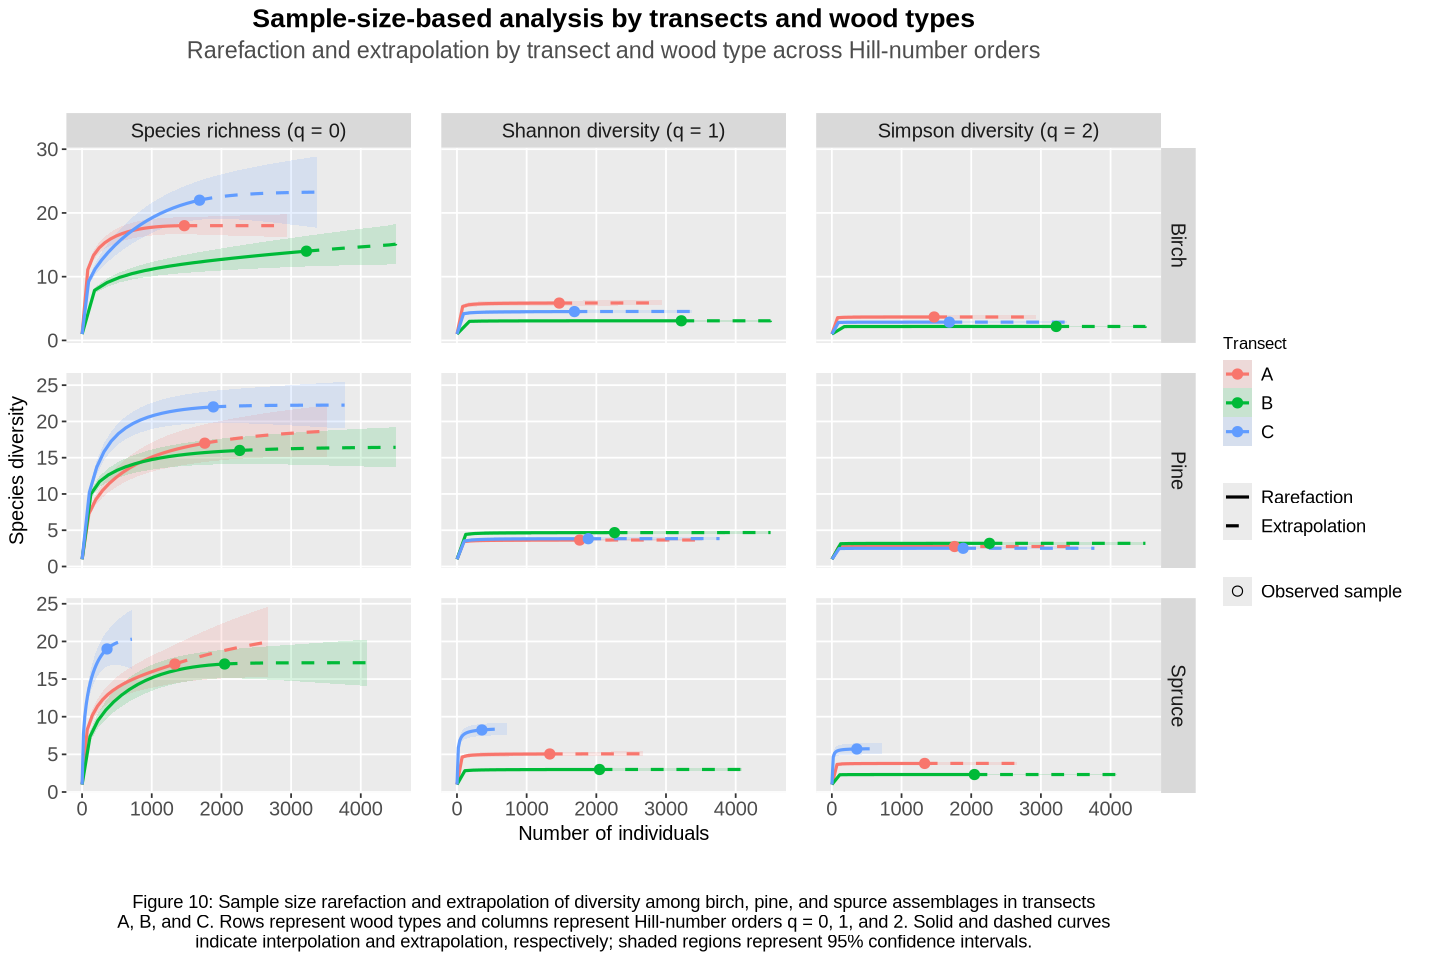

In [56]:
title_text <- paste0(
    "Sample-size-based analysis by transects and wood types"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation by transect and wood type across Hill-number orders"
)

caption_text <- paste0(
    "Figure 10: Sample size rarefaction and extrapolation of diversity among birch, pine, and spurce assemblages ",
    "in transects A, B, and C. Rows represent wood types and columns represent Hill-number orders q = 0, 1, and 2. ",
    "Solid and dashed curves indicate interpolation and extrapolation, respectively; shaded regions represent 95% ",
    "confidence intervals."
)

z.figure2 <- ggplot(plot_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            fill = Transect
        )
    ) +
    geom_ribbon(
        aes(ymin = y.lwr, ymax = y.upr),
        alpha = 0.15,
        linewidth = 0
    ) +
    geom_line(
        aes(linetype = Method),
        linewidth = 0.9
    ) +
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            fill = Transect,
            shape = "Observed sample"
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    facet_grid(
        Wood.Type ~ Order.q,
        scales = "free_y"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_shape_manual(values = c("Observed sample" = 21)) +
    scale_x_continuous(limits = c(0, 4500), oob = squish) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
        linetype = NULL,
        shape = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
z.figure2 

#### Results
Figure 10 displays sample-size-based rarefaction and extrapolation curves comparing saproxylic fungal diversity among birch, pine, and spruce assemblages across Transects A, B, and C, organized by Hill number order.

For species richness (_q = 0_), the birch assemblage in Transect A and the spruce assemblage in Transect B largely reached plateaus. In contrast, birch assemblages in Transects B and C retained upward trajectories during extrapolation, whereas pine assemblages in Transects B and C gradually approached plateaus. Across birch, pine, and spruce assemblages, species richness generally followed the pattern Transect C > Transect A > Transect B. **The confidence intervals widened with increasing extrapolated sample size for birch in Transect C and pine in Transect A, indicating greater uncertainty in species-richness estimates farther beyond the observed sample sizes.**

**No extrapolated segment was shown for the spruce assemblage in Transect C. Across Hill number orders, spruce diversity followed the pattern Transect C > Transect A > Transect B.**

For birch, Shannon (q = 1) and Simpson (q = 2) diversity followed the pattern Transect A > Transect C > Transect B. In contrast, Shannon and Simpson diversity for pine were very similar among the three transects, indicating relatively little transect-level differentiation in higher-order diversity for pine-associated fungal assemblages.

### 4.4. Sample completeness (type = 2)

#### Figure 11: Sample completeness

In [57]:
# Extract sample-completeness data
plot_data <- fortify(inext, type = 2)

# Separate assemblage into transect and wood texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Type = factor(Wood.Type, levels = c("Birch", "Pine", "Spruce"))
    )

# Preserve the observed reference points before converting "Observed" to "Rarefaction"
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat the observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

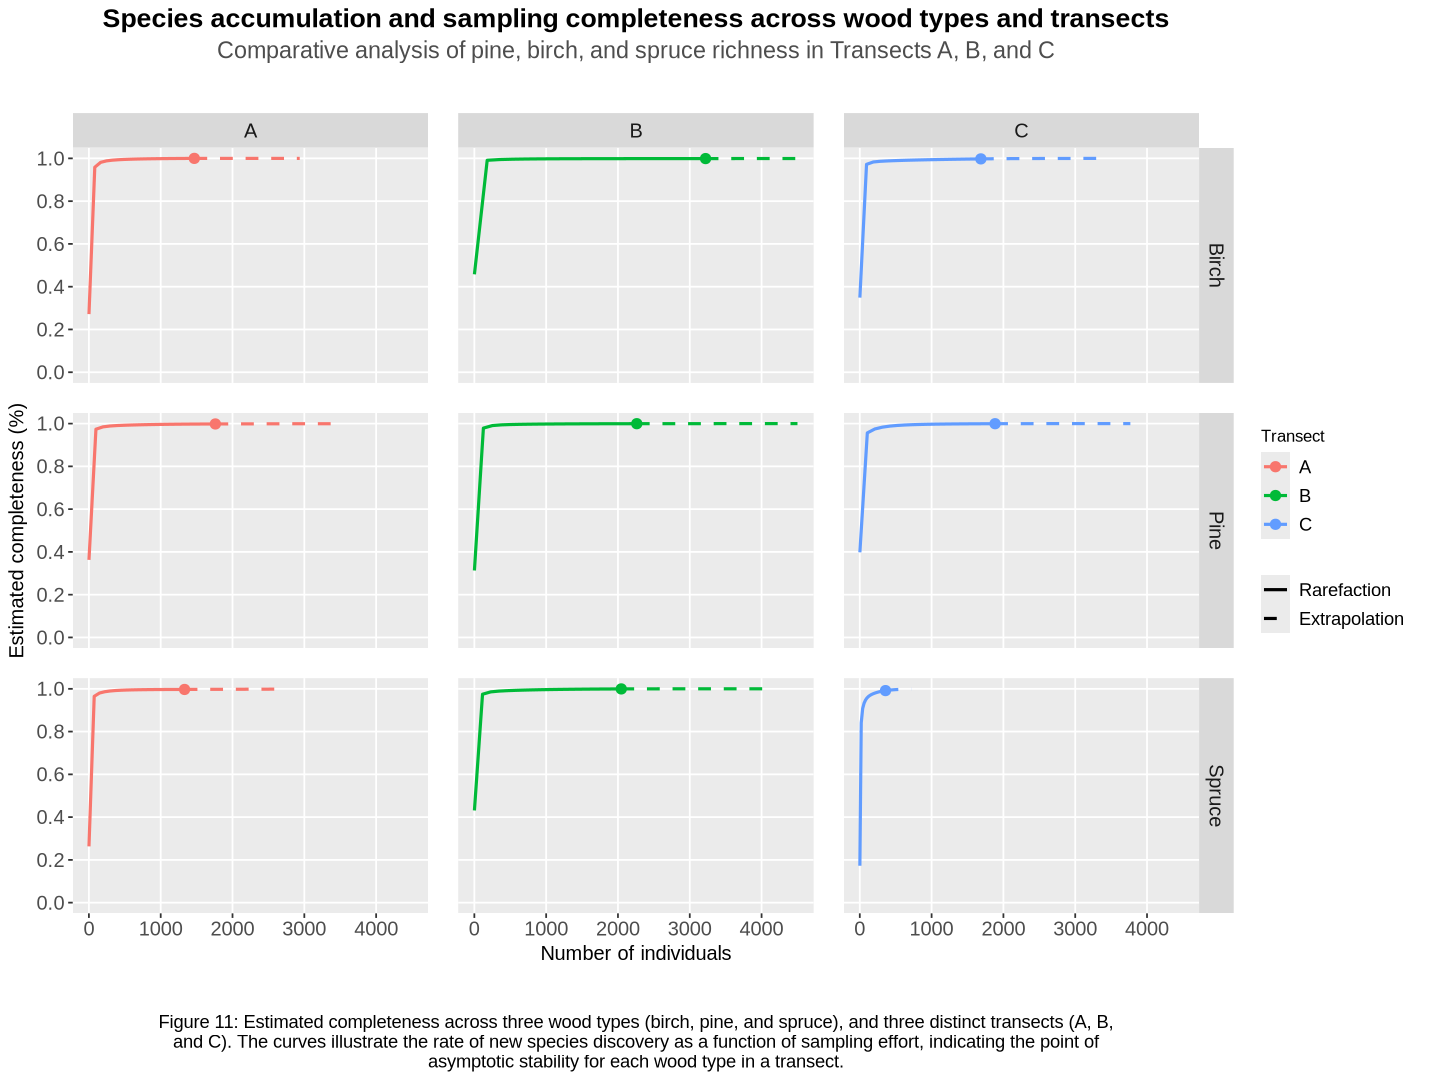

In [58]:
title_text <- paste0(
    "Species accumulation and sampling completeness across wood types and transects"
)

subtitle_text <- paste0(
    "Comparative analysis of pine, birch, and spruce richness in Transects A, B, and C"
)

caption_text <- paste0(
    "Figure 11: Estimated completeness across three wood types (birch, pine, and spruce), and ",
    "three distinct transects (A, B, and C). ",
    "The curves illustrate the rate of new species discovery as a function of sampling effort, ",
    "indicating the point of asymptotic stability for each wood type in a transect."
)

z.figure3 <- ggplot(plot_data,
    aes(
        x = x,
        y = y,
        color = Transect,
        linetype = Method
    )) +
    geom_line(linewidth = 0.9) +
    # Observed/reference sample
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    # Top row = Hardwood
    # Bottom row = Softwood
    # Columns = Transects A, B, C
    facet_grid(
        Wood.Type ~ Transect
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 4500), oob=squish) +
    scale_y_continuous(
        limits = c(0, 1),
        breaks = seq(0, 1, 0.2)
    ) +
    labs(
        x = "Number of individuals",
        y = "Estimated completeness (%)",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 9)
z.figure3

#### Results

Figure 11 illustrates the sample completeness curves for saproxylic fungal assemblages across wood types (birch, pine, and spruce) and transects (A, B, and C). **The curves exhibit rapid initial accumulation followed by asymptotic behavior, suggesting that sampling effort was sufficient to capture most species richness and that richness estimates have stabilized.** 

However, **the curve for spruce in Transect C fails to reach a clear plateau, indicating that the species richness for spruce in Transect C may still be underestimated due to insufficient sampling density.**

### 4.5. Coverage-based analysis (type = 3)

#### Figure 12: Coverage-based analysis

In [59]:
# Use the actual coverage-based iNEXT estimates
plot_data <- inext$iNextEst$coverage_based

# Split Assemblage into Transect and Wood Type
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Type = factor(Wood.Type, levels = c("Birch", "Pine", "Spruce")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve observed/reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

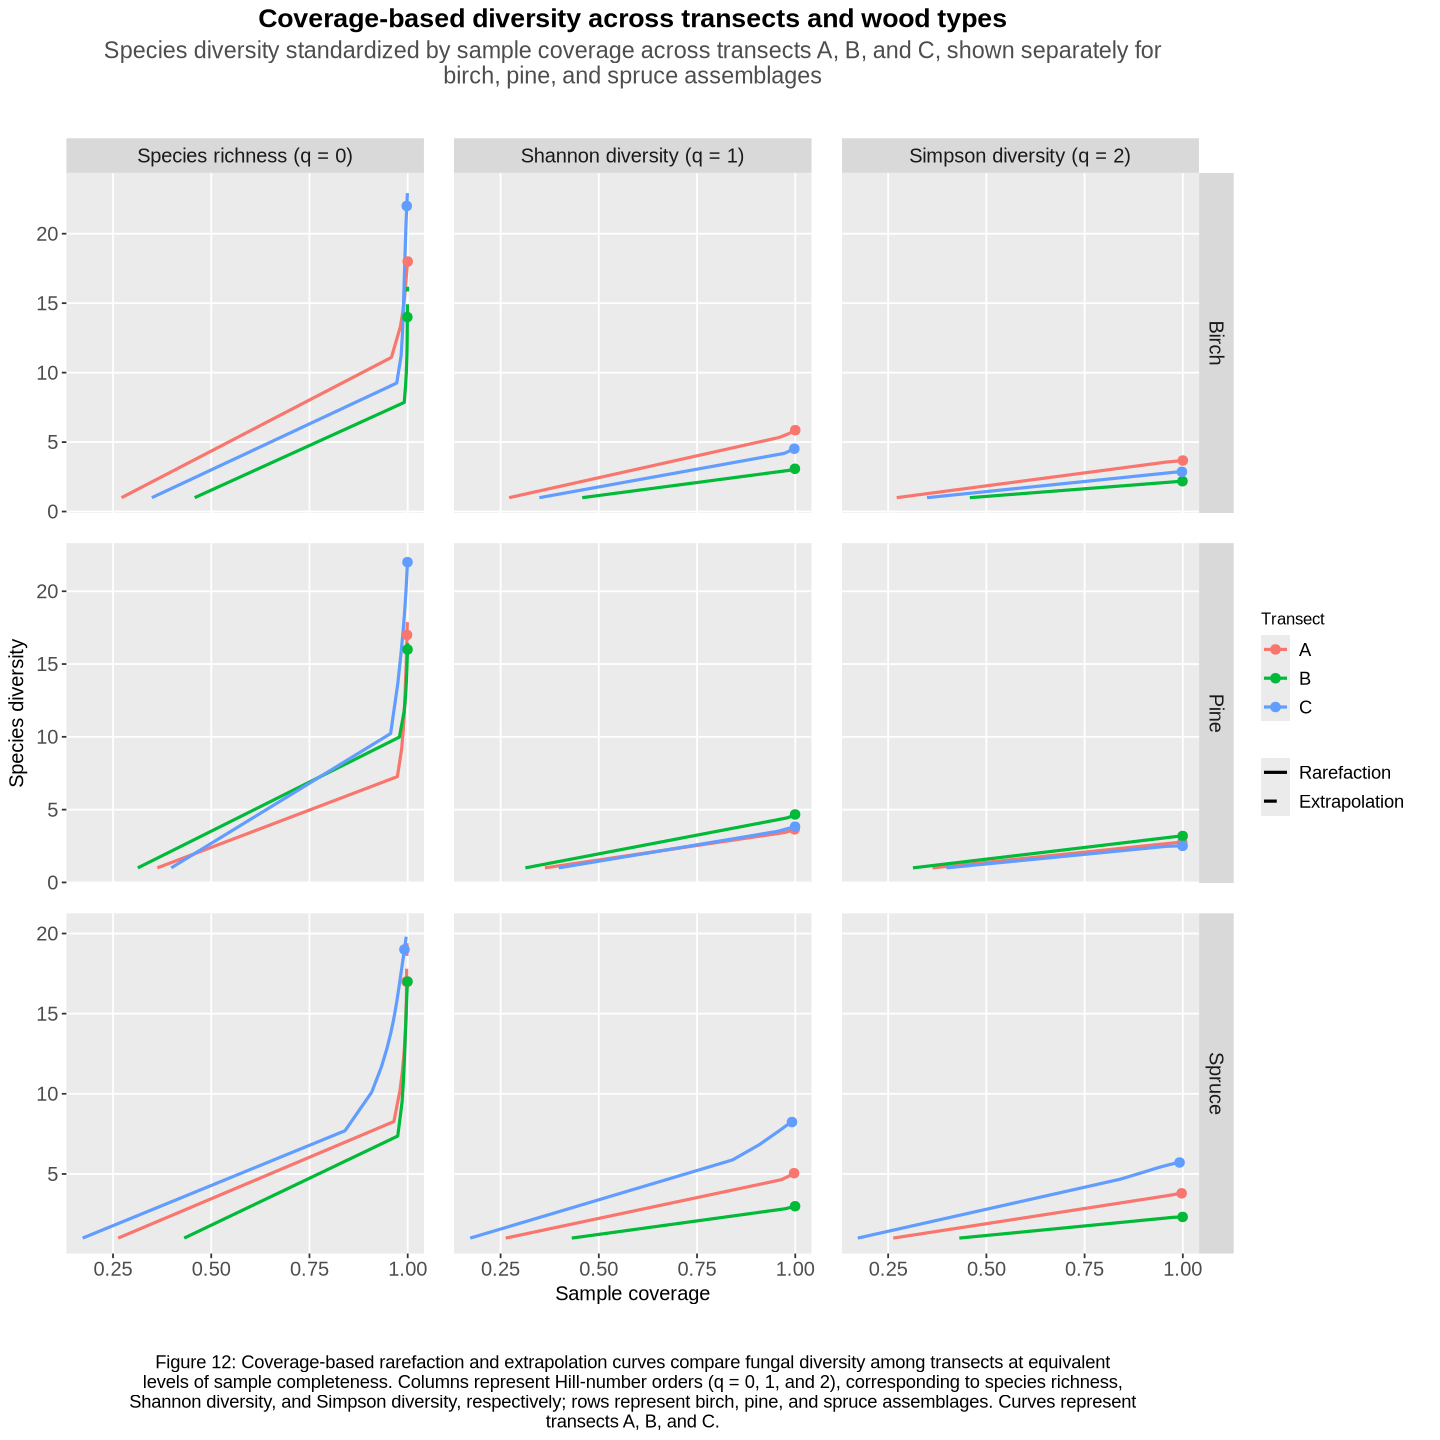

In [60]:
title_text <- paste0(
    "Coverage-based diversity across transects and wood types"
)

subtitle_text <- paste0(
    "Species diversity standardized by sample coverage across transects A, B, and C, shown separately for birch, pine, and spruce assemblages"
)

caption_text <- paste0(
    "Figure 12: Coverage-based rarefaction and extrapolation curves compare fungal diversity among transects ",
    "at equivalent levels of sample completeness. Columns represent Hill-number orders (q = 0, 1, and 2), ",
    "corresponding to species richness, Shannon diversity, and Simpson diversity, respectively; ",
    "rows represent birch, pine, and spruce assemblages. Curves represent transects A, B, and C."
)

z.figure4 <- ggplot(plot_data, aes(x = SC, y = qD)) +
    # Coverage-based diversity curves
    geom_line(
        aes(
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top, Softwood on bottom
    # Hill numbers across columns
    facet_grid(
        Wood.Type ~ Order.q,
        scales = "free_y"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 12)
z.figure4

#### Results
Figure 12 presents coverage-based diversity curves organized by Hill number order, allowing direct comparison of birch, pine, and spruce assemblages across Transects A, B, and C at equivalent levels of sample coverage.

For species richness (_q = 0_), diversity was generally highest in Transect C, while Transects A and B exhibited similar levels of richness across the wood types.

For birch, Shannon (_q = 1_) and Simpson (_q = 2_) diversity followed the pattern Transect A > Transect C > Transect B. In contrast, Shannon and Simpson diversity for pine were broadly comparable among the three transects. For spruce, both diversity measures followed the pattern Transect C > Transect A > Transect B.

## 5. Summary of Results

Saproxylic fungal diversity varied consistently among transects and according to wood substrate. 

### Transect
At the transect level, **Transect B contained the greatest proportion of fungal abundance (46.4%) but the lowest observed species richness (20 species), whereas Transect C had the highest richness (30 species) despite accounting for only 25.4% of total abundance.** 
* Across species richness (q = 0), Shannon diversity (q = 1), and Simpson diversity (q = 2), diversity generally followed the pattern Transect C > Transect A > Transect B.
* Sample-size- and coverage-based analyses showed that most diversity curves approached asymptotes and that this ranking persisted when assemblages were compared at equivalent levels of sample coverage.

### Wood Texture
When assemblages were grouped by wood texture, **softwood consistently supported greater species richness and abundance than hardwood across all three transects.** 
* Species richness for both hardwood and softwood followed the pattern Transect C > Transect A > Transect B.
* In contrast, Shannon and Simpson diversity among hardwood assemblages followed Transect A > Transect C > Transect B, whereas higher-order diversity among softwood assemblages was comparatively similar across transects.
* Most curves approached plateaus, although several assemblages retained upward extrapolation trajectories and widening confidence intervals, indicating greater uncertainty in their estimated species richness.

### Wood Type
Patterns were more variable when assemblages were separated by wood type. 
* Species richness was generally highest in Transect C for birch, pine, and spruce, although differences between Transects A and B were comparatively small for some wood types.
* Birch assemblages showed the pattern Transect A > Transect C > Transect B for Shannon and Simpson diversity, whereas pine assemblages showed relatively little differentiation among transects.
* Spruce assemblages followed Transect C > Transect A > Transect B across Hill-number orders.
* Species-richness estimates also showed substantially greater uncertainty than Shannon and Simpson diversity estimates, particularly for birch in Transect C, pine in Transect A, and birch in Transect B.
* Sample completeness was generally high, although spruce in Transect C showed comparatively incomplete sampling and lacked a clear extrapolated plateau.

### Overall Summary
Overall, the analyses indicate that Transect C generally supported the greatest saproxylic fungal diversity, whereas Transect B supported high fungal abundance but comparatively low diversity. Differences among transects were most pronounced for species richness and varied with wood substrate, while diversity based on common and dominant taxa was generally more stable and precisely estimated.